# City Hotel: khám phá dữ liệu và tính khả thi dự báo

Notebook EDA: chất lượng nhãn, xu hướng, mùa vụ, lag, missingness, holiday/weather, lead time và cancellation. Không train model.

Bản viết lại từ `01_city_hotel_demand_eda.ipynb`, bản cũ được giữ nguyên.
Chọn kernel `.venv`, chạy từ trên xuống (Restart Kernel → Run All).
Nguồn mặc định là snapshot cố định đã lưu, không cần PostgreSQL hoặc `docs/ml` cũ.
Quality PASS là evidence của snapshot, không phải kiểm tra DB mới.
Target là khách của booking cuối cùng không hủy theo ngày đến, không phải occupancy/check-in thực.
Holdout 06–08/2017 đã được xem ở thí nghiệm trước, kết quả là hồi cứu, mang tính khám phá.

## 1. Thiết lập

Chỉ dùng các thư viện đã có trong `ml/requirements.txt`. Mỗi lần chạy tạo
thư mục artifact riêng, không sửa dữ liệu nguồn hoặc kết quả cũ.

In [1]:
import hashlib
import importlib.metadata
import json
import platform
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'pipeline/config/dw_operations.json').is_file())
pd.set_option('display.max_columns', None, 'display.max_rows', None, 'display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

In [2]:
SOURCE_DIR = ROOT / 'artifacts/forecasting/history_demand_causal_methods/20261109T110426_146bf398'
NOTEBOOK_PATH = ROOT / 'notebooks/exploration/01_city_hotel_demand_eda_report.ipynb'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '_' + uuid4().hex[:8]
OUT = ROOT / 'artifacts/forecasting/01_city_hotel_demand_eda_report' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
DAY = pd.Timedelta(days=1)
TRAIN_START, TEST_END = pd.Timestamp('2015-07-01'), pd.Timestamp('2017-08-31')
SEED = 42
print('Artifacts:', OUT.relative_to(ROOT))

Artifacts: artifacts\forecasting\01_city_hotel_demand_eda_report\20261110T043626_2014fe00


In [3]:
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def save_json(name, value):
    with (OUT / name).open('x', encoding='utf-8') as handle:
        json.dump(value, handle, ensure_ascii=False, indent=2, default=str, allow_nan=False)
def save_csv(name, frame):
    frame.to_csv(OUT / name, index=False, float_format='%.12g')
save_json('environment.json', {'python': platform.python_version(), **{
    name: importlib.metadata.version(name) for name in ('numpy', 'pandas', 'matplotlib', 'scikit-learn')}})

## 2. Load data và kiểm tra nguồn

Kiểm tra checksum trước khi đọc. Daily và booking phải thuộc cùng published snapshot,
khóa booking là checksum nguồn + row ordinal. Không gộp dòng vì giống thuộc tính.

In [4]:
inventory = json.loads((SOURCE_DIR / 'input_manifest.json').read_text(encoding='utf-8'))
for name in ('daily_input.csv', 'booking_input.csv', 'provenance.json', 'quality.json'):
    assert sha(SOURCE_DIR / name) == inventory[name], f'Input changed: {name}'
provenance = json.loads((SOURCE_DIR / 'provenance.json').read_text(encoding='utf-8'))
quality = json.loads((SOURCE_DIR / 'quality.json').read_text(encoding='utf-8'))
assert all(q['passed'] and not q['errors'] for q in quality.values())
assert all(q['data_version'] == provenance['data_version'] for q in quality.values())
daily = pd.read_csv(SOURCE_DIR / 'daily_input.csv', parse_dates=['full_date'])
bookings = pd.read_csv(SOURCE_DIR / 'booking_input.csv', parse_dates=['full_date'])
print('Data version:', provenance['data_version'])
pd.DataFrame({'dataset': ['daily', 'booking'], 'rows': [len(daily), len(bookings)]})

Data version: 323b1759-994c-4c66-8ca3-8d73e5a11acb


,dataset,rows
0,daily,793
1,booking,79250


In [5]:
daily_ints = ['date_key', 'observed_total_guests', 'target_guests', 'non_canceled_bookings',
              'guest_valid_booking_count', 'missing_guest_bookings_count',
              'guest_ineligible_booking_count', 'rejected_booking_count', 'excluded_booking_count']
for frame, names in ((daily, daily_ints), (bookings, ['source_row_id', 'is_canceled', 'total_guests'])):
    for name in names:
        values = pd.to_numeric(frame[name], errors='raise')
        frame[name] = values.astype('Int64')
assert pd.DatetimeIndex(daily.full_date).equals(pd.date_range(TRAIN_START, TEST_END))
assert set(daily.data_version) == {provenance['data_version']}
assert daily.guest_data_status.eq('COMPLETE').equals(daily.target_guests.notna())
assert set(bookings.source_file_sha256) == {provenance['source_checksums']['booking']}

In [6]:
valid = bookings[(bookings.is_canceled == 0) & bookings.guest_eligible].copy()
observed = valid.groupby('full_date').total_guests.agg(['sum', 'count'])
observed = observed.reindex(daily.full_date, fill_value=0)
np.testing.assert_array_equal(observed['sum'], daily.observed_total_guests)
np.testing.assert_array_equal(observed['count'], daily.guest_valid_booking_count)
source_hashes = {name: sha(SOURCE_DIR / name) for name in inventory}
old_paths = [p for p in (ROOT / 'notebooks').rglob('*.ipynb') if not p.stem.endswith('_report')]
old_hashes = {str(p.relative_to(ROOT)): sha(p) for p in old_paths}
save_json('source.json', {'snapshot': str(SOURCE_DIR.relative_to(ROOT)), 'provenance': provenance,
                          'input_checksums': source_hashes, 'point_in_time_verified': False})

## 3. Bổ sung thuộc tính phục vụ EDA

Snapshot đã có nhãn, booking được chấp nhận và khóa nguồn. Raw chỉ bổ sung
thuộc tính trên đúng các khóa đó, không đưa lại booking bị loại. Kiểm tra checksum,
date, cancellation và guest totals trước khi phân tích. Weather/holiday tổng hợp
về một dòng/ngày rồi join 1:1. Đây là enrichment offline, không phải snapshot DB mới.

In [7]:
manifest = json.loads((ROOT / 'docs/data_dictionary/operations_source_set.json').read_text(encoding='utf-8'))
config_path = ROOT / 'pipeline/config/dw_operations.json'
assert sha(config_path) == provenance['config_sha256']
config = json.loads(config_path.read_text(encoding='utf-8'))
raw_hashes = {}
for name, spec in manifest['sources'].items():
    assert spec['sha256'] == provenance['source_checksums'][name]
    assert sha(ROOT / spec['file']) == spec['sha256']
    raw_hashes[spec['file']] = spec['sha256']

In [8]:
raw = pd.read_csv(ROOT / manifest['sources']['booking']['file'], keep_default_na=False,
                  dtype={'children': 'string'}, low_memory=False)
raw['source_row_id'] = np.arange(2, len(raw) + 2)
columns = ['source_row_id', 'hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month',
           'arrival_date_day_of_month', 'is_canceled', 'adults', 'children', 'babies',
           'country', 'distribution_channel', 'market_segment', 'customer_type', 'is_repeated_guest']
enriched = bookings.merge(raw[columns], on='source_row_id', how='left',
                           validate='one_to_one', suffixes=('', '_raw'), indicator=True)
assert len(enriched) == len(bookings) and enriched._merge.eq('both').all()
assert enriched.is_canceled.eq(enriched.is_canceled_raw).all()
raw_date = pd.to_datetime(enriched.arrival_date_year.astype(str) + '-' +
    enriched.arrival_date_month + '-' + enriched.arrival_date_day_of_month.astype(str), format='%Y-%B-%d')
assert raw_date.equals(enriched.full_date)

In [9]:
b = enriched.drop(columns=['_merge', 'is_canceled_raw']).copy()
for name in ('adults', 'children', 'babies', 'lead_time', 'is_repeated_guest'):
    original_values = b[name]
    values = pd.to_numeric(original_values.replace({'': np.nan, 'NA': np.nan}), errors='raise')
    b[name] = values.astype('Int64')
total = b[['adults', 'children', 'babies']].sum(axis=1, min_count=3)
assert total.isna().equals(b.total_guests.isna())
np.testing.assert_array_equal(total.dropna(), b.total_guests.dropna())

In [10]:
source_columns = {'country': 'country', 'channel': 'distribution_channel',
                  'market_segment': 'market_segment', 'customer_type': 'customer_type'}
for name, column in source_columns.items():
    spec = config['mappings'][name]
    assert sha(ROOT / spec['file']) == spec['sha256']
    raw_hashes[spec['file']] = spec['sha256']
    mapping = pd.read_csv(ROOT / spec['file']).set_index('source_code').target_code
    b[name + '_code'] = b[column].astype('string').str.strip().str.upper().map(mapping).fillna(spec['unknown_code'])
b['repeat_status'] = np.select([b.is_repeated_guest.eq(0), b.is_repeated_guest.eq(1)], ['NEW', 'REPEAT'], default='UNKNOWN')
family = b.children.gt(0) | b.babies.gt(0)
party_conditions = [~b.guest_eligible.to_numpy(), family.to_numpy(dtype=bool, na_value=False),
                    b.adults.eq(1).to_numpy(dtype=bool, na_value=False), b.adults.eq(2).to_numpy(dtype=bool, na_value=False)]
b['party_type'] = np.select(party_conditions,
                            ['UNKNOWN', 'FAMILY', 'SINGLE', 'COUPLE'], default='OTHER_GROUP')

In [11]:
weather = json.loads((ROOT / manifest['sources']['weather']['file']).read_text(encoding='utf-8'))
assert weather['timezone'] == 'Europe/Lisbon'
assert weather['daily_units']['temperature_2m_mean'] == '°C'
assert weather['daily_units']['precipitation_sum'] == 'mm'
context = pd.DataFrame({'full_date': pd.to_datetime(weather['daily']['time']),
    'temperature_mean': weather['daily']['temperature_2m_mean'], 'precipitation': weather['daily']['precipitation_sum']})
daily_all = daily.merge(context, on='full_date', how='left', validate='one_to_one')
assert daily_all[['temperature_mean', 'precipitation']].notna().all().all()

In [12]:
holidays = pd.read_csv(ROOT / manifest['sources']['holiday']['file'], parse_dates=['date'])
holiday_groups = holidays.groupby('date')
holiday_names = holiday_groups.holiday_name.agg(list)
national_dates = set(holidays.loc[holidays.scope.eq('national'), 'date'])
lisboa_dates = set(holidays.loc[holidays.scope.eq('Lisboa'), 'date'])
daily_all['holiday_names'] = daily_all.full_date.map(holiday_names).map(lambda names: names if isinstance(names, list) else [])
daily_all['is_holiday'] = daily_all.full_date.isin(holiday_names.index)
daily_all['has_national_holiday'] = daily_all.full_date.isin(national_dates)
daily_all['has_lisboa_holiday'] = daily_all.full_date.isin(lisboa_dates)
daily_all['temperature_status'] = 'COMPLETE'
daily_all['precipitation_status'] = 'COMPLETE'

In [13]:
daily_all['day_of_week'] = daily_all.full_date.dt.day_of_week + 1
daily_all['month'] = daily_all.full_date.dt.month
daily_all['year'] = daily_all.full_date.dt.year
daily_all['avg_party_size'] = daily_all.observed_total_guests / daily_all.guest_valid_booking_count.where(daily_all.guest_valid_booking_count.gt(0))
counts = b.groupby('full_date').is_canceled.agg(['size', 'sum']).reindex(daily_all.full_date, fill_value=0)
daily_all['total_bookings'] = counts['size'].to_numpy()
daily_all['total_cancellations'] = counts['sum'].to_numpy()
save_json('enrichment.json', {'raw_checksums': raw_hashes, 'booking_join': 'source checksum + CSV ordinal, one_to_one',
                            'context_join': 'one_to_one on calendar date', 'database_access': False})

## 4. Phạm vi EDA và tiền xử lý

Chỉ khám phá target/booking trong development đến 31/05/2017. Holdout chỉ xuất hiện
ở metadata số ngày/completeness. Không bù target, giữ zero/outlier, giữ trục lịch khi lag.
EDA không có kiến trúc mô hình, train/validation/test hoặc metric dự báo.

In [14]:
DEV_END = pd.Timestamp('2017-05-31')
WD = {1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat', 7: 'Sun'}
HAVE_BOOKINGS = True
daily_dev = daily_all[daily_all.full_date.le(DEV_END)].copy()
observed_dev = daily_dev[daily_dev.target_guests.notna()].copy()
booking_dev = b[b.full_date.le(DEV_END)].copy()
y_dev = daily_dev.set_index('full_date').target_guests.astype(float).asfreq('D')
metadata = daily_all.assign(partition=np.where(daily_all.full_date.le(DEV_END), 'development', 'holdout_metadata_only'))
metadata.groupby('partition').agg(days=('full_date', 'size'), complete=('target_guests', 'count'))

,days,complete
partition,,
development,701,626
holdout_metadata_only,92,87


In [15]:
def assert_dev(frame, col='full_date'):
    dates = pd.to_datetime(frame.index if col is None else frame[col])
    assert len(dates) == 0 or dates.max() <= DEV_END
    return frame
def md(text):
    display(Markdown(text))

In [16]:
def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = np.divide(k, n, out=np.full_like(k, np.nan), where=n > 0)
    den = 1 + z**2 / n
    ctr = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return ctr - half, ctr + half

### In các biến dùng trong EDA

Đây là các biến phân tích mô tả, không phải ma trận feature đã chọn để train.
In đầy đủ tên/kiểu dữ liệu và mẫu trên development. Target, outcome cuối cùng,
observed weather và các count đồng thời không mặc nhiên khả dụng khi dự báo tương lai.

In [17]:
daily_fields = ['full_date', 'target_guests', 'day_of_week', 'month', 'year',
    'is_holiday', 'has_national_holiday', 'has_lisboa_holiday', 'holiday_names', 'temperature_mean', 'precipitation',
    'guest_data_status', 'booking_data_status', 'guest_ineligible_booking_count',
    'missing_guest_bookings_count', 'rejected_booking_count', 'excluded_booking_count',
    'observed_total_guests', 'guest_valid_booking_count', 'non_canceled_bookings',
    'total_bookings', 'total_cancellations', 'avg_party_size']
booking_fields = ['full_date', 'lead_time', 'country_code', 'channel_code', 'market_segment_code',
    'customer_type_code', 'repeat_status', 'party_type', 'total_guests', 'guest_eligible',
    'is_canceled', 'adults', 'children', 'babies']
for name, frame, fields in (('daily', daily_dev, daily_fields), ('booking', booking_dev, booking_fields)):
    catalog = pd.DataFrame({'field': fields, 'dtype': [str(frame[field].dtype) for field in fields],
                            'missing_development': [int(frame[field].isna().sum()) for field in fields]})
    print(f'{name}: {len(fields)} biến phân tích')
    display(catalog)
    display(frame[fields].head(3).T.rename_axis('field'))
    save_csv(name + '_field_catalog.csv', catalog)

daily: 23 biến phân tích
booking: 14 biến phân tích


,field,dtype,missing_development
0,full_date,datetime64[us],0
1,target_guests,Int64,75
2,day_of_week,int32,0
3,month,int32,0
4,year,int32,0
5,is_holiday,bool,0
6,has_national_holiday,bool,0
7,has_lisboa_holiday,bool,0
8,holiday_names,object,0
9,temperature_mean,float64,0


,0,1,2
field,,,
full_date,2015-07-01 00:00:00,2015-07-02 00:00:00,2015-07-03 00:00:00
target_guests,116,1,18
day_of_week,3,4,5
month,7,7,7
year,2015,2015,2015
is_holiday,False,False,False
has_national_holiday,False,False,False
has_lisboa_holiday,False,False,False
holiday_names,[],[],[]


,field,dtype,missing_development
0,full_date,datetime64[us],0
1,lead_time,Int64,0
2,country_code,str,0
3,channel_code,str,0
4,market_segment_code,str,0
5,customer_type_code,str,0
6,repeat_status,str,0
7,party_type,str,0
8,total_guests,Int64,4
9,guest_eligible,bool,0


,0,1,2
field,,,
full_date,2015-07-01 00:00:00,2015-07-01 00:00:00,2015-07-01 00:00:00
lead_time,6,88,65
country_code,PRT,PRT,PRT
channel_code,TA/TO,TA/TO,TA/TO
market_segment_code,OFFLINE TA/TO,ONLINE TA,ONLINE TA
customer_type_code,TRANSIENT,TRANSIENT,TRANSIENT
repeat_status,NEW,NEW,NEW
party_type,SINGLE,COUPLE,SINGLE
total_guests,1,2,1


## 5. Phân phối target và chất lượng nhãn

Tóm tắt trên ngày COMPLETE, log1p chỉ để hiển thị. Ngày zero hợp lệ và ngày lớn
được giữ nguyên. Bảng completeness theo tháng giúp nhận biết thiên lệch khi chỉ dùng COMPLETE.

In [18]:
yo = assert_dev(observed_dev).target_guests.astype(float)
target_summary = yo.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame('guests')
target_summary

,guests
count,626.000000
mean,106.845048
std,54.462493
min,0.000000
1%,2.000000
25%,69.000000
50%,106.000000
75%,145.000000
99%,231.750000
max,298.000000


In [19]:
print('Zero hợp lệ:', int(yo.eq(0).sum()), '| Skew:', round(yo.skew(), 3))
completeness = daily_dev.assign(month=daily_dev.full_date.dt.to_period('M')).groupby('month').agg(
    calendar_days=('full_date', 'size'), complete_days=('target_guests', 'count'))
completeness

Zero hợp lệ: 5 | Skew: 0.218


,calendar_days,complete_days
month,,
2015-07,31,29
2015-08,31,26
2015-09,30,27
2015-10,31,28
2015-11,30,29
2015-12,31,30
2016-01,31,31
2016-02,29,24
2016-03,31,28


In [20]:
save_csv('target_summary.csv', target_summary.reset_index())
save_csv('development_completeness.csv', completeness.reset_index())

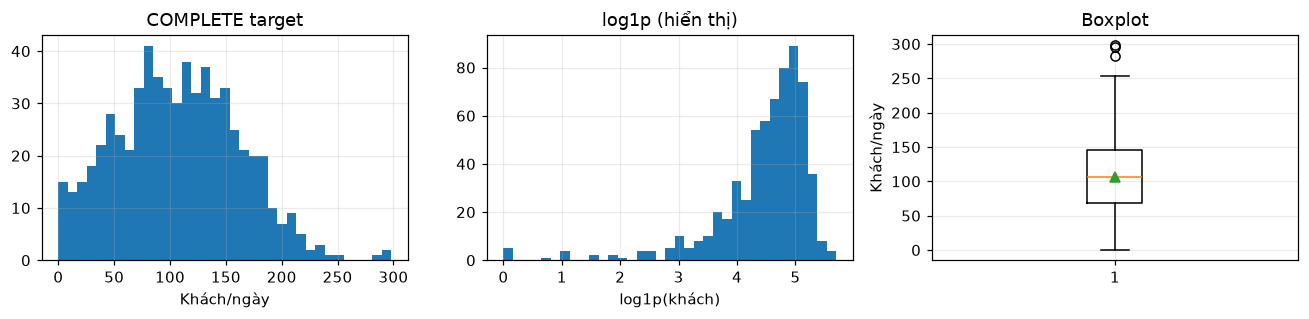

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
axes[0].hist(yo, bins=35)
axes[0].set(title='COMPLETE target', xlabel='Khách/ngày')
axes[1].hist(np.log1p(yo), bins=35)
axes[1].set(title='log1p (hiển thị)', xlabel='log1p(khách)')
axes[2].boxplot(yo, showmeans=True)
axes[2].set(title='Boxplot', ylabel='Khách/ngày')
fig.tight_layout()
fig.savefig(OUT / 'distribution.png')
plt.show()

## 6. Xu hướng và biến động

Rolling mean/std/count 28 ngày, mean/std cần ít nhất 14 nhãn. NULL giữ nguyên trên trục lịch.

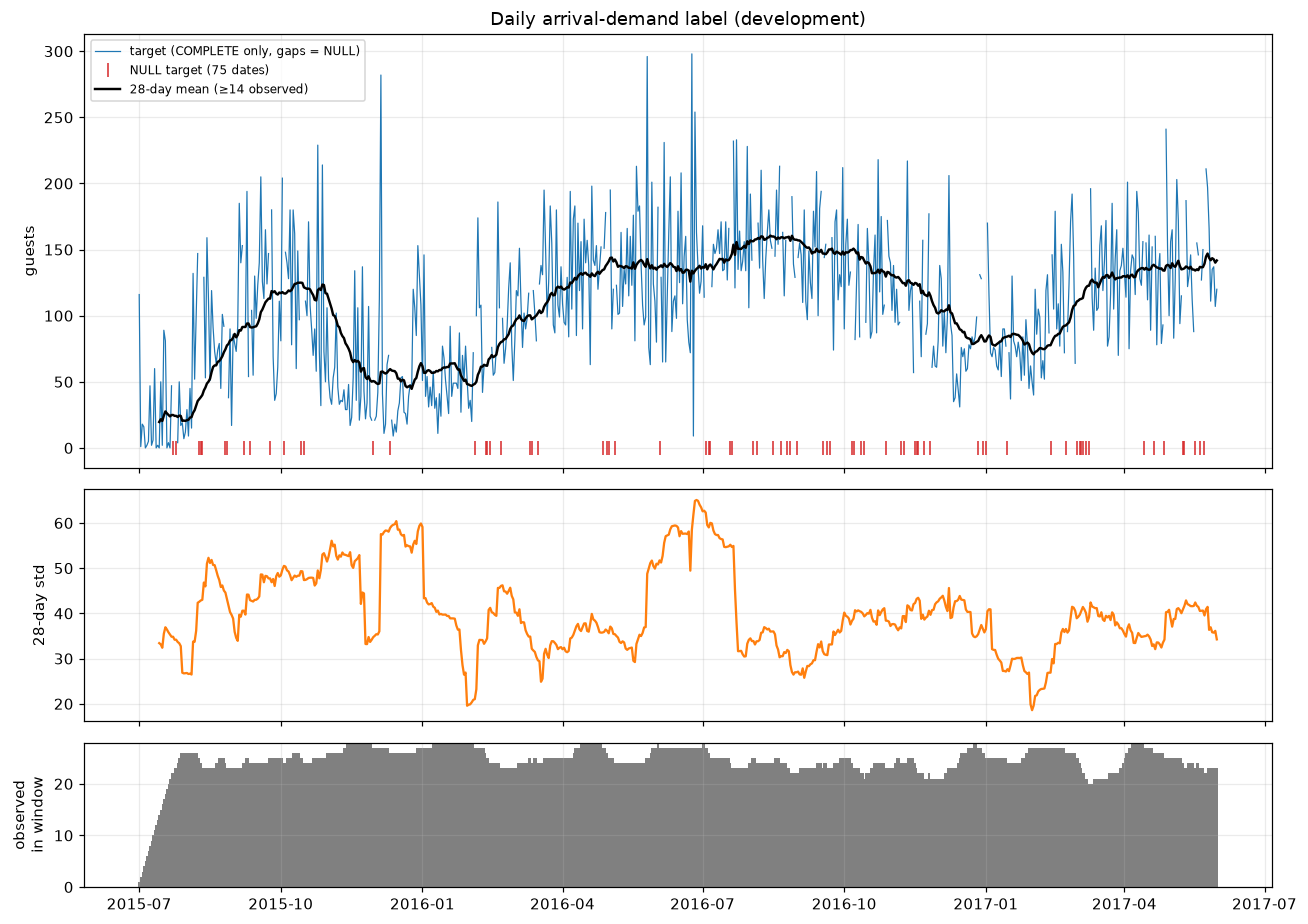

,calendar_days,n_complete,mean,median,std,cv
full_date,,,,,,
2015-07,31,29,23.00,7.0,31.20,1.36
2015-08,31,26,77.00,76.5,41.05,0.53
2015-09,30,27,114.44,113.0,47.55,0.42
2015-10,31,28,118.46,107.0,52.71,0.44
2015-11,30,29,50.21,38.0,33.55,0.67
2015-12,31,30,60.63,41.5,57.79,0.95
2016-01,31,31,50.94,49.0,25.83,0.51
2016-02,29,24,90.29,77.0,43.72,0.48
2016-03,31,28,120.21,116.0,31.65,0.26


In [22]:
yd = assert_dev(y_dev.to_frame('y'), col=None)['y']
roll_mean = yd.rolling(28, min_periods=14).mean()
roll_std  = yd.rolling(28, min_periods=14).std()
roll_n    = yd.rolling(28, min_periods=1).count()
fig, ax = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, gridspec_kw={'height_ratios': [3, 1.6, 1]})
ax[0].plot(yd.index, yd.values, lw=.8, color='tab:blue', label='target (COMPLETE only, gaps = NULL)')
miss = yd[yd.isna()].index
ax[0].plot(miss, np.zeros(len(miss)), '|', color='tab:red', ms=9, label=f'NULL target ({len(miss)} dates)')
ax[0].plot(roll_mean.index, roll_mean.values, color='k', lw=1.6, label='28-day mean (≥14 observed)')
ax[0].set_ylabel('guests')
ax[0].legend(loc='upper left', fontsize=8)
ax[0].set_title('Daily arrival-demand label (development)')
ax[1].plot(roll_std.index, roll_std.values, color='tab:orange')
ax[1].set_ylabel('28-day std')
ax[2].bar(roll_n.index, roll_n.values, width=1, color='gray')
ax[2].set_ylabel('observed\nin window')
ax[2].set_ylim(0, 28)
plt.tight_layout()
plt.show()
g = yd.groupby(yd.index.to_period('M'))
monthly = pd.DataFrame({'calendar_days': g.size(), 'n_complete': g.count(), 'mean': g.mean(), 'median': g.median(), 'std': g.std()})
monthly['cv'] = monthly['std'] / monthly['mean']
monthly.round(2)

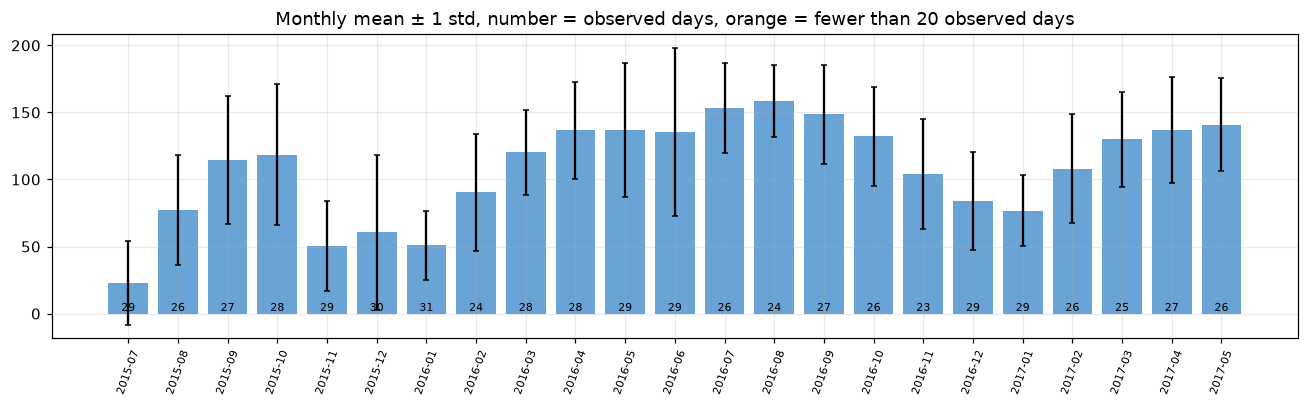

In [23]:
fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(len(monthly))
ax.bar(x, monthly['mean'], yerr=monthly['std'], capsize=2, color=np.where(monthly.n_complete < 20, '#e0a96d', '#6aa3d5'))
for i, n in enumerate(monthly.n_complete): ax.text(i, 2, str(n), ha='center', fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels([str(p) for p in monthly.index], rotation=70, fontsize=7)
ax.set_title('Monthly mean ± 1 std, number = observed days, orange = fewer than 20 observed days')
plt.tight_layout()
plt.show()

## 7. Mùa vụ theo thứ và tháng

Mean/median/boxplot theo lịch, weekday index theo tiểu giai đoạn. Chỉ hơn hai chu kỳ năm, không khẳng định mùa vụ ổn định.

In [24]:
wd = yd.index.day_of_week + 1
wd_tab = pd.DataFrame({'calendar_days': pd.Series(wd).value_counts().sort_index(), 'n_complete': yd.groupby(wd).count(),
                       'mean': yd.groupby(wd).mean(), 'median': yd.groupby(wd).median(), 'std': yd.groupby(wd).std()})
wd_tab.index = [WD[i] for i in wd_tab.index]
wd_tab.round(2)

,calendar_days,n_complete,mean,median,std
Mon,100,96,116.04,129.5,55.20
Tue,100,90,82.60,83.5,43.39
Wed,101,86,103.17,99.0,48.19
Thu,100,87,108.21,115.0,55.96
Fri,100,86,128.97,134.5,57.48
Sat,100,91,108.70,106.0,51.33
Sun,100,90,100.46,101.0,58.42


In [25]:
ydn = yd.dropna()
moy = pd.DataFrame({'years_with_data': ydn.groupby(ydn.index.month).apply(lambda s: s.index.year.nunique()),
                    'n_complete': yd.groupby(yd.index.month).count(), 'mean': yd.groupby(yd.index.month).mean(),
                    'median': yd.groupby(yd.index.month).median(), 'std': yd.groupby(yd.index.month).std()})
moy.index.name = 'month'
moy.round(2)

,years_with_data,n_complete,mean,median,std
month,,,,,
1,2,60,63.47,58.5,29.09
2,2,50,99.48,95.0,42.62
3,2,53,124.89,119.0,33.55
4,2,55,136.69,138.0,37.47
5,2,55,138.73,128.0,43.15
6,1,29,135.34,125.0,62.67
7,2,55,84.55,89.0,73.06
8,2,50,116.00,129.0,53.68
9,2,54,131.50,130.5,45.56


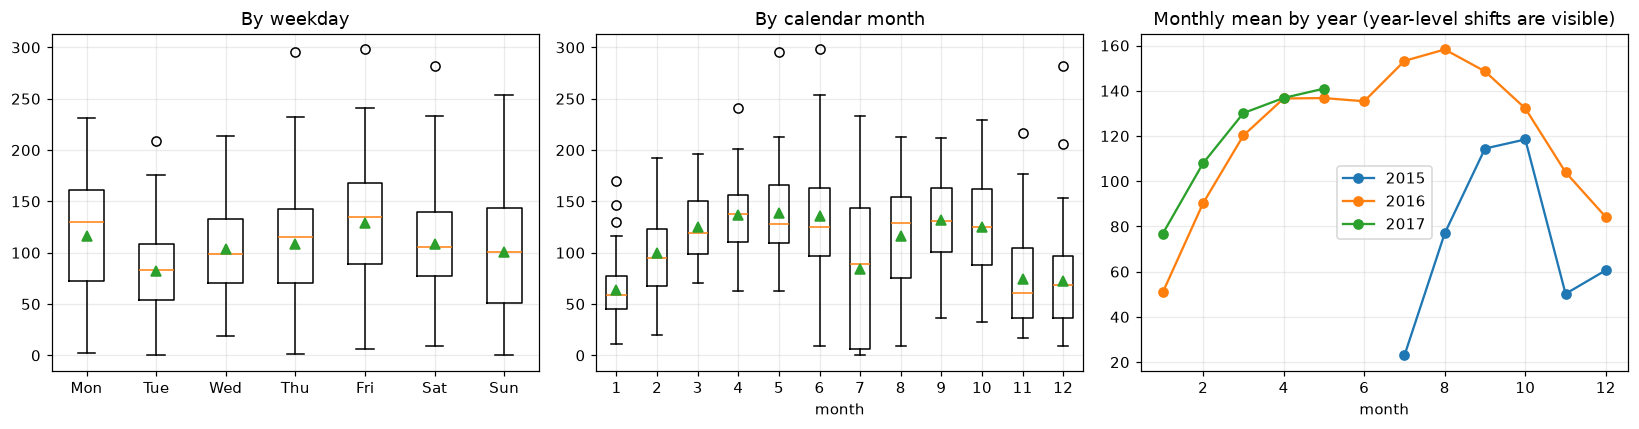

**Weekday index per sub-period** (weekday mean ÷ period mean, 1.0 = average day) — descriptive stability check:

wd,Mon,Tue,Wed,Thu,Fri,Sat,Sun,n_complete
period,,,,,,,,
2015H2,0.98,0.78,1.25,0.78,1.28,1.20,0.75,169
2016H1,1.05,0.77,0.91,1.11,1.24,0.98,0.97,169
2016H2,1.09,0.84,0.90,1.05,1.14,0.98,0.98,155
2017 Jan–May,1.13,0.73,0.91,1.05,1.19,0.95,1.02,133


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].boxplot([yd[wd == i].dropna() for i in range(1, 8)], showmeans=True)
ax[0].set_xticklabels([WD[i] for i in range(1, 8)])
ax[0].set_title('By weekday')
ax[1].boxplot([yd[yd.index.month == m].dropna() for m in range(1, 13)], showmeans=True)
ax[1].set_xticklabels(range(1, 13))
ax[1].set_title('By calendar month')
ax[1].set_xlabel('month')
ym = yd.groupby([yd.index.year, yd.index.month]).mean().unstack(0)
for yr in ym.columns: ax[2].plot(ym.index, ym[yr], marker='o', label=str(yr))
ax[2].set(title='Monthly mean by year (year-level shifts are visible)', xlabel='month')
ax[2].legend()
plt.tight_layout()
plt.show()
def period_of(d):
    return ('2015H2' if d <= pd.Timestamp('2015-12-31') else '2016H1' if d <= pd.Timestamp('2016-06-30')
            else '2016H2' if d <= pd.Timestamp('2016-12-31') else '2017 Jan–May')
dfw = yd.to_frame('y')
dfw['period'] = [period_of(d) for d in dfw.index]
dfw['wd'] = [WD[i] for i in wd]
order = ['2015H2', '2016H1', '2016H2', '2017 Jan–May']
widx = dfw.groupby(['period', 'wd']).y.mean().unstack('wd')[list(WD.values())].div(dfw.groupby('period').y.mean(), axis=0).loc[order]
md('**Weekday index per sub-period** (weekday mean ÷ period mean, 1.0 = average day) — descriptive stability check:')
widx.round(2).assign(n_complete=dfw.groupby('period').y.count().loc[order])

## 8. Tương quan trễ trên trục lịch

Pearson lag 1–28, chỉ dùng cặp đầy đủ và báo số cặp. So sánh raw với residual đã trừ weekday mean development.

In [27]:
def lag_table(y, lags):
    rows = []
    for L in lags:
        pr = pd.concat([y.rename('y'), y.shift(L).rename('lag')], axis=1).dropna()
        rows.append({'lag': L, 'n_pairs': len(pr), 'pearson': pr['y'].corr(pr['lag']) if len(pr) > 2 else np.nan})
    return pd.DataFrame(rows).set_index('lag')
LAGS = list(range(1, 29))
raw_lag = lag_table(yd, LAGS)
res = yd - yd.groupby(yd.index.day_of_week).transform('mean')
adj_lag = lag_table(res, LAGS)
both = raw_lag.add_suffix('_raw').join(adj_lag.add_suffix('_weekday_adj')).drop(columns='n_pairs_weekday_adj').rename(columns={'n_pairs_raw': 'n_pairs'})
both.loc[[1, 7, 14, 21, 28]].round(3)

,n_pairs,pearson_raw,pearson_weekday_adj
lag,,,
1,564,0.432,0.458
7,551,0.543,0.513
14,546,0.474,0.440
21,537,0.445,0.407
28,539,0.401,0.362


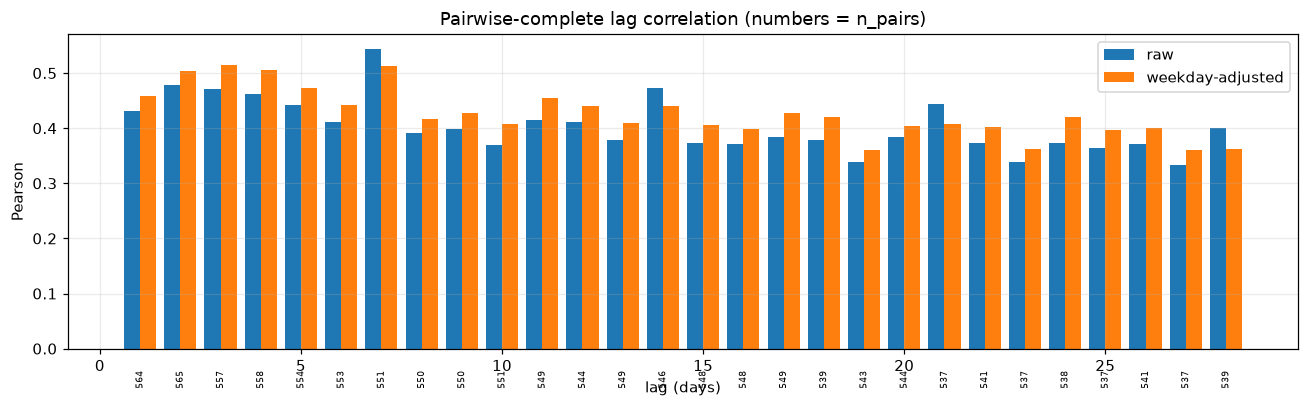

In [28]:
fig, ax = plt.subplots(figsize=(12, 3.8))
w = .4
ax.bar(raw_lag.index - w/2, raw_lag.pearson, w, label='raw')
ax.bar(adj_lag.index + w/2, adj_lag.pearson, w, label='weekday-adjusted')
for L in LAGS: ax.text(L, -0.04, str(int(raw_lag.loc[L, 'n_pairs'])), ha='center', va='top', fontsize=6, rotation=90)
ax.axhline(0, color='k', lw=.6)
ax.set(title='Pairwise-complete lag correlation (numbers = n_pairs)', xlabel='lag (days)', ylabel='Pearson')
ax.legend()
plt.tight_layout()
plt.show()

In [29]:
ok = yd.notna()
run = (ok != ok.shift(fill_value=ok.iloc[0])).cumsum()
segs = pd.DataFrame([{'start': g.index.min().date(), 'end': g.index.max().date(), 'days': len(g)} for _, g in yd[ok].groupby(run[ok])])
md(f'**Contiguous COMPLETE segments:** {len(segs)} runs, longest {segs.days.max()} days, {int((segs.days >= 28).sum())} runs ≥ 28 days.')
segs.sort_values('days', ascending=False).head(10).reset_index(drop=True)

**Contiguous COMPLETE segments:** 62 runs, longest 54 days, 7 runs ≥ 28 days.

,start,end,days
0,2015-12-12,2016-02-03,54
1,2015-10-17,2015-11-29,44
2,2016-03-17,2016-04-26,41
3,2017-03-10,2017-04-13,35
4,2016-11-27,2016-12-26,30
5,2016-06-04,2016-07-02,29
6,2016-05-06,2016-06-02,28
7,2017-01-16,2017-02-11,27
8,2015-07-01,2015-07-22,22
9,2016-02-22,2016-03-10,18


In [30]:
SEG_MIN = 28
rows = []
for s in segs[segs.days >= SEG_MIN].itertuples():
    t = lag_table(yd.loc[str(s.start):str(s.end)], [1, 7, 14])
    rows.append({'start': s.start, 'end': s.end, 'days': s.days, **{f'lag{L}': t.loc[L, 'pearson'] for L in [1, 7, 14]},
                 **{f'n{L}': int(t.loc[L, 'n_pairs']) for L in [1, 7, 14]}})
seg_corr = pd.DataFrame(rows)
md(f'**Per-segment lag correlation** (segments ≥ {SEG_MIN} days, raw series):')
seg_corr.round(3)

**Per-segment lag correlation** (segments ≥ 28 days, raw series):

,start,end,days,lag1,lag7,lag14,n1,n7,n14
0,2015-10-17,2015-11-29,44,0.077,0.097,0.000,43,37,30
1,2015-12-12,2016-02-03,54,0.437,-0.067,-0.392,53,47,40
2,2016-03-17,2016-04-26,41,-0.267,0.106,0.180,40,34,27
3,2016-05-06,2016-06-02,28,-0.264,0.261,0.114,27,21,14
4,2016-06-04,2016-07-02,29,-0.515,0.391,0.392,28,22,15
5,2016-11-27,2016-12-26,30,0.401,-0.177,0.112,29,23,16
6,2017-03-10,2017-04-13,35,-0.175,0.632,0.635,34,28,21


In [31]:
pr_rows = []
for L in [1, 7, 14]:
    pr = pd.concat([yd.rename('y'), yd.shift(L).rename('lag')], axis=1).dropna()
    pr['period'] = [period_of(d) for d in pr.index]
    for p, g in pr.groupby('period'): pr_rows.append({'lag': L, 'period': p, 'n_pairs': len(g), 'pearson': g.y.corr(g.lag)})
pd.DataFrame(pr_rows).pivot(index='period', columns='lag', values=['pearson', 'n_pairs']).loc[order].round(3)

pearson               n_pairs              
lag               1      7      14      1      7      14
period                                                  
2015H2         0.409  0.335  0.271   156.0  147.0  140.0
2016H1         0.222  0.520  0.453   159.0  158.0  156.0
2016H2         0.306  0.520  0.408   131.0  130.0  133.0
2017 Jan–May   0.395  0.533  0.415   118.0  116.0  117.0

## 9. Missingness và selection bias

Tỷ lệ PARTIAL theo lịch, clustering/run length, activity proxy chuẩn hóa weekday và Mann–Whitney mô tả, chưa chỉnh nhiều phép thử hoặc phụ thuộc thời gian.

In [32]:
dd = assert_dev(daily_dev).copy()
dd['partial'] = dd.guest_data_status.ne('COMPLETE')
dd['wd'] = dd.day_of_week.map(WD)
dd['ym'] = dd.full_date.dt.to_period('M')
def rate(g): return pd.Series({'days': len(g), 'partial_days': int(g.partial.sum()), 'partial_rate': g.partial.mean()})
dd.groupby('wd').apply(rate).loc[list(WD.values())].round(3)

,days,partial_days,partial_rate
wd,,,
Mon,100.0,4.0,0.040
Tue,100.0,10.0,0.100
Wed,101.0,15.0,0.149
Thu,100.0,13.0,0.130
Fri,100.0,14.0,0.140
Sat,100.0,9.0,0.090
Sun,100.0,10.0,0.100


In [33]:
dd.groupby(dd.full_date.dt.month).apply(rate).round(3).rename_axis('month')

,days,partial_days,partial_rate
month,,,
1,62.0,2.0,0.032
2,57.0,7.0,0.123
3,62.0,9.0,0.145
4,60.0,5.0,0.083
5,62.0,7.0,0.113
6,30.0,1.0,0.033
7,62.0,7.0,0.113
8,62.0,12.0,0.194
9,60.0,6.0,0.100


In [34]:
s = dd.partial.astype(int)
prev = s.shift(1)
pd.Series({'P(PARTIAL)': s.mean(), 'P(PARTIAL | previous day PARTIAL)': s[prev == 1].mean(),
                   'P(PARTIAL | previous day COMPLETE)': s[prev == 0].mean()}).round(3).to_frame('clustering check')

,clustering check
P(PARTIAL),0.107
P(PARTIAL | previous day PARTIAL),0.187
P(PARTIAL | previous day COMPLETE),0.098


In [35]:
runs_ = (s != s.shift(fill_value=s.iloc[0])).cumsum()
pl = s[s == 1].groupby(runs_[s == 1]).size()
md(f'PARTIAL runs: {len(pl)} runs, longest {int(pl.max())} day(s), {int((pl == 1).sum())} are isolated single days.')
md('**What makes the PARTIAL days PARTIAL** (counts valid on every day):')
dd.loc[dd.partial, ['guest_ineligible_booking_count', 'missing_guest_bookings_count', 'rejected_booking_count']].astype('float64').describe().T.round(2)

PARTIAL runs: 61 runs, longest 3 day(s), 50 are isolated single days.

**What makes the PARTIAL days PARTIAL** (counts valid on every day):

,count,mean,std,min,25%,50%,75%,max
guest_ineligible_booking_count,75.0,1.08,0.27,1.0,1.0,1.0,1.0,2.0
missing_guest_bookings_count,75.0,1.08,0.27,1.0,1.0,1.0,1.0,2.0
rejected_booking_count,75.0,0.21,0.72,0.0,0.0,0.0,0.0,5.0


In [36]:
dd.loc[dd.partial].guest_ineligible_booking_count.value_counts().sort_index().to_frame('PARTIAL days')

,PARTIAL days
guest_ineligible_booking_count,
1,69
2,6


In [37]:
proxy = ['non_canceled_bookings', 'total_bookings', 'total_cancellations', 'rejected_booking_count']
X = dd[proxy].astype('float64')
base = X[~dd.partial.values].groupby(dd.loc[~dd.partial, 'day_of_week'].values).mean()
ratio = pd.DataFrame(X.values / base.reindex(dd.day_of_week).values, index=dd.index, columns=proxy)
summ = ratio.groupby(dd.partial.map({False: 'COMPLETE', True: 'PARTIAL'})).agg(['count', 'median', 'mean']).round(3)
md('**Activity proxies ÷ COMPLETE-day weekday mean** (1.0 = typical COMPLETE day of the same weekday):')
summ

**Activity proxies ÷ COMPLETE-day weekday mean** (1.0 = typical COMPLETE day of the same weekday):

non_canceled_bookings              total_bookings               total_cancellations               rejected_booking_count             
                         count median  mean          count median   mean               count median   mean                  count median  mean
partial                                                                                                                                       
COMPLETE                   626  1.002  1.00            626  0.973  1.000                 626  0.795  1.000                    626    0.0  1.00
PARTIAL                     75  1.157  1.14             75  1.084  1.158                  75  0.896  1.189                     75    0.0  2.39

In [38]:
try:
    from scipy.stats import mannwhitneyu
    pv = {c: mannwhitneyu(ratio.loc[dd.partial, c].dropna(), ratio.loc[~dd.partial, c].dropna()).pvalue for c in proxy}
    display(pd.Series(pv).round(4).to_frame('Mann-Whitney p (descriptive, no multiplicity correction)'))
except ImportError:
    print('scipy not installed: rank test skipped')

,"Mann-Whitney p (descriptive, no multiplicity correction)"
non_canceled_bookings,0.0079
total_bookings,0.0279
total_cancellations,0.0369
rejected_booking_count,0.0557


## 10. Ngày lễ và thời tiết

So sánh raw/weekday-adjusted và nhóm tên lễ, số mẫu lễ nhỏ. Đây là liên hệ mô tả, không phải tác động nhân quả.

In [39]:
od = assert_dev(observed_dev).copy()
od['y'] = od.target_guests.astype('float64')
od['r_wd'] = od.y / od.groupby('day_of_week').y.transform('mean')
od['r_wd_mo'] = od.r_wd / od.groupby('month').r_wd.transform('mean')
for c in ['is_holiday', 'has_national_holiday', 'has_lisboa_holiday']:
    od[c] = od[c].astype(bool)
def hol_tab(col):
    return od.groupby(col).agg(n=('y', 'size'), mean=('y', 'mean'), median=('y', 'median'),
                               mean_r_wd=('r_wd', 'mean'), median_r_wd=('r_wd', 'median')).round(3)
for col in ['is_holiday', 'has_national_holiday', 'has_lisboa_holiday']:
    md(f'**{col}**')
    display(hol_tab(col))
md('Weekday composition of holiday days (confounding check):')
pd.crosstab(od.is_holiday.map({True: 'holiday', False: 'non-holiday'}), od.day_of_week.map(WD))[list(WD.values())]

**is_holiday**

,n,mean,median,mean_r_wd,median_r_wd
is_holiday,,,,,
False,607,106.357,106.0,0.996,1.016
True,19,122.421,112.0,1.121,1.115


**has_national_holiday**

,n,mean,median,mean_r_wd,median_r_wd
has_national_holiday,,,,,
False,608,106.372,106.0,0.996,1.016
True,18,122.833,112.0,1.128,1.143


**has_lisboa_holiday**

,n,mean,median,mean_r_wd,median_r_wd
has_lisboa_holiday,,,,,
False,625,106.832,106.0,1.000,1.017
True,1,115.000,115.0,0.991,0.991


Weekday composition of holiday days (confounding check):

day_of_week,Mon,Tue,Wed,Thu,Fri,Sat,Sun
is_holiday,,,,,,,
holiday,4,3,1,3,4,1,3
non-holiday,92,87,85,84,82,90,87


In [40]:
names = od[['holiday_names', 'r_wd', 'y']].explode('holiday_names').dropna(subset=['holiday_names'])
if len(names):
    md('**Holiday names** (n = observed days, small n ⇒ no conclusion):')
    display(names.groupby('holiday_names').agg(n=('y', 'size'), mean=('y', 'mean'), mean_r_wd=('r_wd', 'mean')).sort_values('n', ascending=False).head(15).round(2))

**Holiday names** (n = observed days, small n ⇒ no conclusion):

,n,mean,mean_r_wd
holiday_names,,,
Assunção de Nossa Senhora,2,131.5,1.17
Dia da Liberdade,2,107.5,1.06
Dia de Natal,2,64.5,0.59
Imaculada Conceição,2,112.0,1.06
Páscoa,2,99.5,0.99
Ano Novo,1,51.0,0.40
"Dia de Portugal, de Camões e das Comunidades Portuguesas",1,205.0,1.59
Corpo de Deus,1,296.0,2.74
Dia de Todos os Santos,1,104.0,1.26


In [41]:
W = od[['y', 'r_wd', 'r_wd_mo', 'temperature_mean', 'precipitation']]
sp = W.corr(method='spearman')[['temperature_mean', 'precipitation']].drop(index=['temperature_mean', 'precipitation']).round(3)
sp['n_pairs'] = len(W.dropna())
md('**Spearman correlation with observed weather** (development, COMPLETE days):')
sp

**Spearman correlation with observed weather** (development, COMPLETE days):

,temperature_mean,precipitation,n_pairs
y,0.172,-0.012,626
r_wd,0.194,-0.019,626
r_wd_mo,0.015,0.010,626


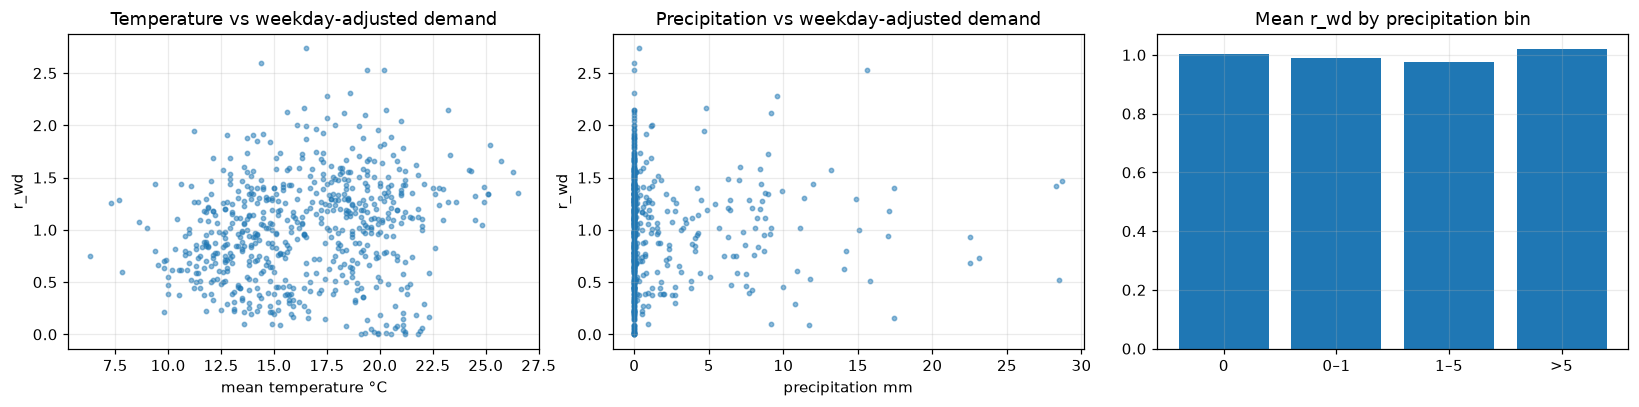

,n,mean_r_wd,mean_r_wd_mo
precipitation,,,
0,427,1.002,0.996
0–1,69,0.988,0.968
1–5,62,0.975,1.003
>5,68,1.020,1.054


In [42]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].scatter(od.temperature_mean, od.r_wd, s=8, alpha=.5)
ax[0].set(xlabel='mean temperature °C', ylabel='r_wd', title='Temperature vs weekday-adjusted demand')
ax[1].scatter(od.precipitation, od.r_wd, s=8, alpha=.5)
ax[1].set(xlabel='precipitation mm', ylabel='r_wd', title='Precipitation vs weekday-adjusted demand')
pbin = pd.cut(od.precipitation, [-.001, 0, 1, 5, np.inf], labels=['0', '0–1', '1–5', '>5'])
ptab = od.groupby(pbin, observed=True).agg(n=('y', 'size'), mean_r_wd=('r_wd', 'mean'), mean_r_wd_mo=('r_wd_mo', 'mean'))
ax[2].bar(ptab.index.astype(str), ptab.mean_r_wd)
ax[2].set(title='Mean r_wd by precipitation bin')
plt.tight_layout()
plt.show()
ptab.round(3)

## 11. Lead time của booking

Quantile và ECDF theo accepted/non-canceled/eligible/canceled, phân nhóm segment/channel. Thuộc tính đều là final-state.

In [43]:
bd = assert_dev(booking_dev)
pops = {'A all accepted': bd, 'B non-canceled': bd[bd.is_canceled == 0],
            'C non-canceled & guest-eligible': bd[(bd.is_canceled == 0) & bd.guest_eligible], 'D canceled': bd[bd.is_canceled == 1]}
rows = []
for k, v in pops.items():
        lt = v.lead_time.dropna().astype('float64')
        rows.append({'population': k, 'n': len(v), 'lead_time NULL': int(v.lead_time.isna().sum()), 'mean': lt.mean(), 'p10': lt.quantile(.1),
                     'median': lt.median(), 'p90': lt.quantile(.9), 'p99': lt.quantile(.99),
                     'share = 0d': (lt == 0).mean(), 'share ≤ 7d': (lt <= 7).mean(), 'share ≥ 90d': (lt >= 90).mean(), 'share ≥ 180d': (lt >= 180).mean()})
pd.DataFrame(rows).set_index('population').round(3)

,n,lead_time NULL,mean,p10,median,p90,p99,share = 0d,share ≤ 7d,share ≥ 90d,share ≥ 180d
population,,,,,,,,,,,
A all accepted,68601,0,103.930,4.0,68.0,276.0,444.0,0.041,0.144,0.415,0.201
B non-canceled,39774,0,72.022,1.0,44.0,188.0,335.0,0.065,0.218,0.302,0.111
C non-canceled & guest-eligible,39693,0,72.064,1.0,44.0,188.0,335.0,0.064,0.218,0.302,0.111
D canceled,28827,0,147.955,18.0,107.0,326.0,538.0,0.008,0.042,0.572,0.325


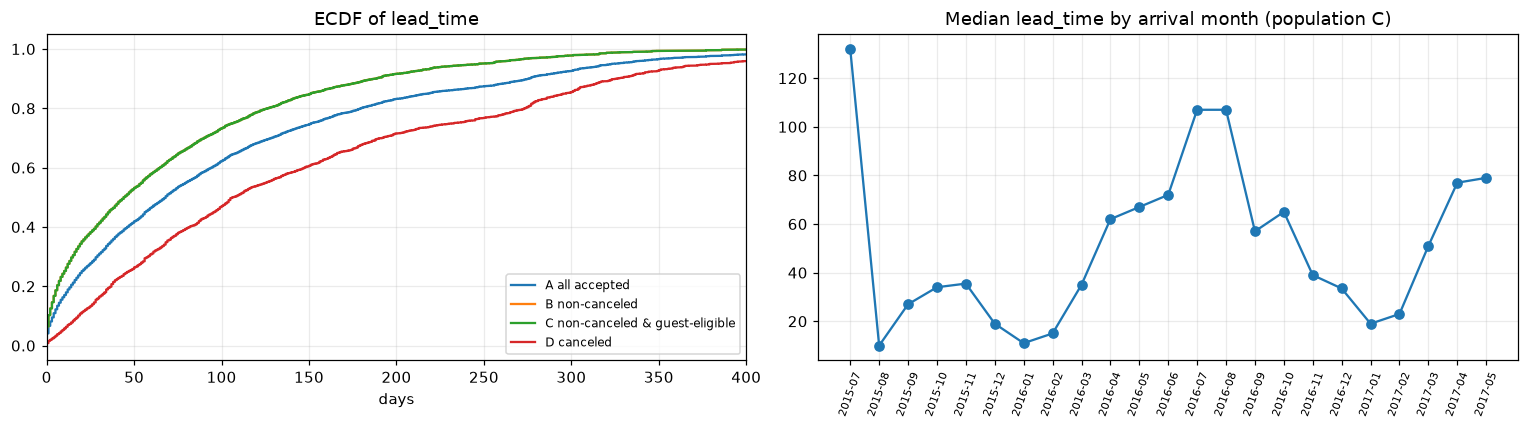

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, v in pops.items():
        lt = np.sort(v.lead_time.dropna().astype('float64').values)
        ax[0].plot(lt, np.arange(1, len(lt) + 1) / len(lt), label=k)
ax[0].set(xlim=(0, 400), title='ECDF of lead_time', xlabel='days')
ax[0].legend(fontsize=8)
c = pops['C non-canceled & guest-eligible']
med = c.assign(lt=c.lead_time.astype('float64')).groupby(c.full_date.dt.to_period('M')).lt.median()
ax[1].plot(med.index.astype(str), med.values, marker='o')
ax[1].set(title='Median lead_time by arrival month (population C)')
ax[1].tick_params(axis='x', rotation=70, labelsize=7)
plt.tight_layout()
plt.show()

In [45]:
def lead_by(col, top=12):
        d = c.assign(lt=c.lead_time.astype('float64')).groupby(col).agg(n=('lt', 'size'), median=('lt', 'median'), p90=('lt', lambda s: s.quantile(.9)),
                                                                         share_ge90=('lt', lambda s: (s >= 90).mean()))
        return d.sort_values('n', ascending=False).head(top).round(3)
for col in ['market_segment_code', 'channel_code']:
        md(f'**Lead time by `{col}` (population C)**')
        display(lead_by(col))

**Lead time by `market_segment_code` (population C)**

,n,median,p90,share_ge90
market_segment_code,,,,
ONLINE TA,20294,43.0,163.0,0.279
OFFLINE TA/TO,8565,75.0,270.0,0.441
DIRECT,4149,11.0,131.0,0.173
GROUPS,3967,72.0,240.0,0.438
CORPORATE,2135,6.0,51.0,0.040
COMPLEMENTARY,428,2.0,25.0,0.023
AVIATION,155,3.0,10.6,0.000


**Lead time by `channel_code` (population C)**

,n,median,p90,share_ge90
channel_code,,,,
TA/TO,32574,55.0,197.0,0.339
DIRECT,4606,9.0,123.0,0.158
CORPORATE,2377,6.0,88.0,0.098
GDS,136,9.5,43.0,0.007


## 12. Cancellation và khoảng tin cậy mô tả

Tỷ lệ từ sum(cancel)/count booking, Wilson 95% CI, đánh dấu nhóm n<30.
Phân nhóm segment, channel, customer type, repeat, country, lead bucket, tháng và thứ.
Không coi các phân nhóm final-state là feature đã được biết tại origin.

In [46]:
bd = assert_dev(booking_dev)
def rate_by(frame, column):
    result = frame.groupby(column, observed=True).agg(n=('is_canceled', 'size'), canceled=('is_canceled', 'sum'))
    result['cancel_rate'] = result.canceled / result.n
    result['ci_lo'], result['ci_hi'] = wilson(result.canceled, result.n)
    result['small_n'] = result.n.lt(30)
    return result.sort_values('n', ascending=False)
for column in ('market_segment_code', 'channel_code', 'customer_type_code', 'repeat_status', 'country_code'):
    md(f'**{column}**')
    display(rate_by(bd, column).head(12).round(3))

**market_segment_code**

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
market_segment_code,,,,,,
ONLINE TA,32116,11791,0.367,0.362,0.372,False
OFFLINE TA/TO,15085,6507,0.431,0.423,0.439,False
GROUPS,12969,8993,0.693,0.685,0.701,False
DIRECT,5039,872,0.173,0.163,0.184,False
CORPORATE,2716,574,0.211,0.196,0.227,False
COMPLEMENTARY,482,51,0.106,0.081,0.136,False
AVIATION,192,37,0.193,0.143,0.254,False
UNKNOWN,2,2,1.0,0.342,1.000,True


**channel_code**

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
channel_code,,,,,,
TA/TO,59637,27014,0.453,0.449,0.457,False
DIRECT,5671,1043,0.184,0.174,0.194,False
CORPORATE,3119,732,0.235,0.220,0.250,False
GDS,170,34,0.2,0.147,0.266,False
UNKNOWN,4,4,1.0,0.510,1.000,True


**customer_type_code**

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
customer_type_code,,,,,,
TRANSIENT,50214,23053,0.459,0.455,0.463,False
TRANSIENT-PARTY,15830,4641,0.293,0.286,0.300,False
CONTRACT,2295,1105,0.481,0.461,0.502,False
GROUP,262,28,0.107,0.075,0.150,False


**repeat_status**

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
repeat_status,,,,,,
NEW,66821,28406,0.425,0.421,0.429,False
REPEAT,1780,421,0.237,0.217,0.257,False


**country_code**

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
country_code,,,,,,
PRT,28316,18358,0.648,0.643,0.654,False
FRA,7639,1371,0.179,0.171,0.188,False
DEU,4856,854,0.176,0.165,0.187,False
ESP,4102,1134,0.276,0.263,0.290,False
GBR,4010,1171,0.292,0.278,0.306,False
ITA,2912,1050,0.361,0.343,0.378,False
BRA,1547,615,0.398,0.373,0.422,False
BEL,1510,305,0.202,0.183,0.223,False
NLD,1329,263,0.198,0.177,0.220,False


In [47]:
buckets = pd.cut(bd.lead_time.astype(float), [-1, 0, 7, 30, 90, 180, np.inf],
                 labels=['0', '1–7', '8–30', '31–90', '91–180', '181+'])
by_lead = rate_by(bd.assign(lead_bucket=buckets), 'lead_bucket').sort_index()
by_month = rate_by(bd.assign(arr_month=bd.full_date.dt.to_period('M')), 'arr_month').sort_index()
by_weekday = rate_by(bd.assign(weekday=bd.full_date.dt.day_of_week), 'weekday').sort_index()
by_lead.round(3)

,n,canceled,cancel_rate,ci_lo,ci_hi,small_n
lead_bucket,,,,,,
0,2801,235,0.084,0.074,0.095,False
1–7,7099,981,0.138,0.130,0.146,False
8–30,11357,3540,0.312,0.303,0.320,False
31–90,19024,7644,0.402,0.395,0.409,False
91–180,14707,7139,0.485,0.477,0.493,False
181+,13613,9288,0.682,0.674,0.690,False


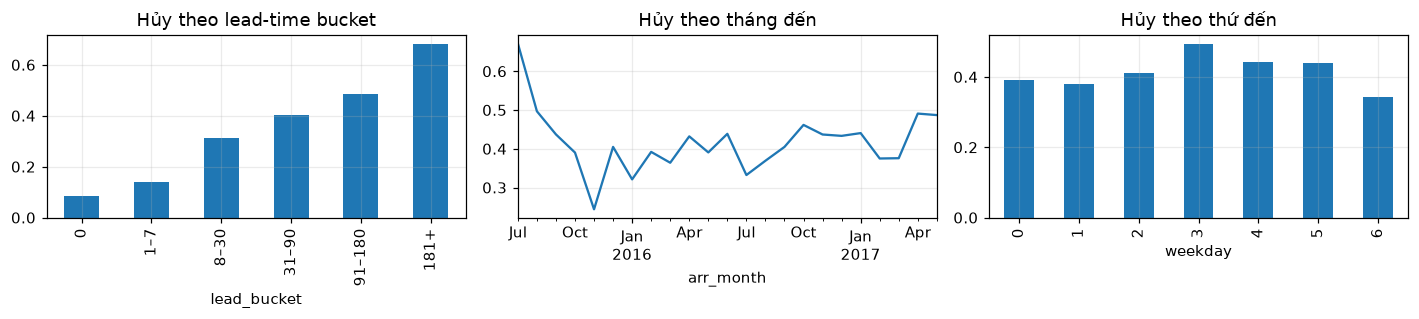

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
by_lead.cancel_rate.plot.bar(ax=axes[0], title='Hủy theo lead-time bucket')
by_month.cancel_rate.plot(ax=axes[1], title='Hủy theo tháng đến')
by_weekday.cancel_rate.plot.bar(ax=axes[2], title='Hủy theo thứ đến')
fig.tight_layout()
fig.savefig(OUT / 'cancellation.png')
plt.show()
save_csv('cancellation_by_lead.csv', by_lead.reset_index())

## 13. Party size và phân rã lượng khách

Phân bố party size, tỷ trọng khách theo nhóm, party type theo rule DW.
Kiểm tra booking reconstruction trước khi mô tả, log decomposition chỉ dùng ngày target>0.
Những đại lượng đồng thời này không phải feature sẵn có cho dự báo tương lai.

In [49]:
elig = bd[(bd.is_canceled == 0) & bd.guest_eligible]
by_day = elig.groupby('full_date').agg(guests=('total_guests', 'sum'), n=('total_guests', 'size'))
by_day = by_day.reindex(daily_dev.full_date, fill_value=0)
def size_dist(frame):
    sizes = frame.total_guests.astype(float)
    groups = sizes.map(lambda n: 'NULL' if pd.isna(n) else '5+' if n >= 5 else str(int(n)))
    return groups.value_counts(normalize=True)
pd.concat({'accepted': size_dist(bd), 'canceled': size_dist(bd[bd.is_canceled == 1]),
                   'label population': size_dist(elig)}, axis=1).fillna(0).round(3)

,accepted,canceled,label population
total_guests,,,
2,0.683,0.737,0.645
1,0.206,0.170,0.232
3,0.088,0.073,0.099
4,0.021,0.020,0.023
0,0.001,0.000,0.000
5+,0.001,0.001,0.001
NULL,0.000,0.000,0.000


In [50]:
group = elig.total_guests.clip(upper=5)
(elig.total_guests.groupby(group).sum() / elig.total_guests.sum()).to_frame('guest_share')

,guest_share
total_guests,
1,0.121218
2,0.672952
3,0.155378
4,0.047335
5,0.003116


In [51]:
pd.concat({'accepted': bd.party_type.value_counts(normalize=True),
                   'label population': elig.party_type.value_counts(normalize=True)}, axis=1).fillna(0).round(3)

,accepted,label population
party_type,,
COUPLE,0.678,0.639
SINGLE,0.206,0.232
FAMILY,0.062,0.071
OTHER_GROUP,0.053,0.058
UNKNOWN,0.001,0.000


In [52]:
dc = assert_dev(observed_dev)[['full_date', 'target_guests', 'guest_valid_booking_count', 'avg_party_size']].astype({'target_guests': 'float64', 'guest_valid_booking_count': 'float64'})
dc = dc[(dc.target_guests > 0) & (dc.guest_valid_booking_count > 0) & dc.avg_party_size.notna()]
lt_, ln_, la_ = np.log(dc.target_guests), np.log(dc.guest_valid_booking_count), np.log(dc.avg_party_size)
v = lt_.var()
md(f'**Variance of log(target)** over {len(dc)} COMPLETE development days with target > 0 (the {len(observed_dev) - len(dc)} excluded days are valid zero labels):')
pd.Series({'log(# eligible bookings)': ln_.var() / v, 'log(mean party size)': la_.var() / v,
                   '2 × covariance': 2 * np.cov(ln_, la_)[0, 1] / v}).round(3).to_frame('share of Var[log target]')

**Variance of log(target)** over 621 COMPLETE development days with target > 0 (the 5 excluded days are valid zero labels):

,share of Var[log target]
log(# eligible bookings),0.930
log(mean party size),0.035
2 × covariance,0.035


In [53]:
dc[['target_guests', 'guest_valid_booking_count', 'avg_party_size']].corr().round(3)

,target_guests,guest_valid_booking_count,avg_party_size
target_guests,1.000,0.953,0.281
guest_valid_booking_count,0.953,1.000,0.022
avg_party_size,0.281,0.022,1.000


## 14. Khả năng dùng history và OTB

Snapshot ETL chứng minh nguồn nhất quán, không chứng minh thông tin đã có ở năm 2015–2017.
Lead_time/arrival/party/status cuối cùng không thay thế được event log hoặc cutoff snapshot.
Weather chỉ có quan sát, không có forecast vintage, lịch lễ chưa có announcement vintage.

In [54]:
availability = pd.DataFrame([
    ('Calendar ngày đích', 'VERIFIED', 'Tính xác định từ ngày'),
    ('Publication delay của nhãn', 'UNVERIFIABLE', 'Không có timestamp công bố nhãn'),
    ('Creation date = arrival − lead_time', 'ASSUMED', 'Proxy từ final-state'),
    ('Active OTB tại origin', 'UNVERIFIABLE', 'Không có lịch sử thay đổi booking/status/party'),
    ('Observed weather ngày đích', 'UNAVAILABLE AT ORIGIN', 'Không phải forecast vintage'),
    ('Ngày công bố lịch lễ', 'UNVERIFIABLE', 'Chỉ có final calendar'),
], columns=['information', 'status', 'reason'])
availability

,information,status,reason
0,Calendar ngày đích,VERIFIED,Tính xác định từ ngày
1,Publication delay của nhãn,UNVERIFIABLE,Không có timestamp công bố nhãn
2,Creation date = arrival − lead_time,ASSUMED,Proxy từ final-state
3,Active OTB tại origin,UNVERIFIABLE,Không có lịch sử thay đổi booking/status/party
4,Observed weather ngày đích,UNAVAILABLE AT ORIGIN,Không phải forecast vintage
5,Ngày công bố lịch lễ,UNVERIFIABLE,Chỉ có final calendar


In [55]:
avail = yd.notna().astype(int)
sup = pd.DataFrame({f'trailing {w}d': avail.rolling(w, min_periods=w).sum() / w for w in [7, 14, 28]}).dropna()
md('**History support by origin** — share of trailing days with a COMPLETE label (distribution over development origins):')
sup.describe(percentiles=[.05, .25, .5]).T[['count', 'mean', '5%', '25%', '50%', 'min']].round(3)

**History support by origin** — share of trailing days with a COMPLETE label (distribution over development origins):

,count,mean,5%,25%,50%,min
trailing 7d,674.0,0.890,0.571,0.857,1.000,0.286
trailing 14d,674.0,0.890,0.714,0.857,0.929,0.571
trailing 28d,674.0,0.892,0.786,0.857,0.893,0.714


In [56]:
pd.DataFrame({'share of origins with ALL trailing labels': (sup == 1).mean(),
                      'share with ≥ 80 % of trailing labels': (sup >= .8).mean()}).round(3)

,share of origins with ALL trailing labels,share with ≥ 80 % of trailing labels
trailing 7d,0.518,0.791
trailing 14d,0.288,0.772
trailing 28d,0.107,0.915


In [57]:
last_seen = yd.index.to_series().where(yd.notna()).ffill()
gap = (yd.index.to_series() - last_seen).dt.days
md(f'Origins whose own label y(t) is NULL: {int(yd.isna().sum())} of {len(yd)}, the most recent COMPLETE label is ≥ 1 day old on those, '
   f'up to {int(gap.max())} day(s) stale. **Whether y(t) was even published by the end of day t is UNVERIFIABLE.**')

Origins whose own label y(t) is NULL: 75 of 701, the most recent COMPLETE label is ≥ 1 day old on those, up to 3 day(s) stale. **Whether y(t) was even published by the end of day t is UNVERIFIABLE.**

In [58]:
Gnet   = elig
Ggross = bd[bd.guest_eligible]
rows = []
for h in range(1, 8):
        net_h, gross_h = Gnet.loc[Gnet.lead_time >= h, 'total_guests'].sum(), Ggross.loc[Ggross.lead_time >= h, 'total_guests'].sum()
        rows.append({'h (days)': h, 'share of label guests with lead_time ≥ h (hindsight)': net_h / Gnet.total_guests.sum(),
                     'gross ÷ net guests with lead_time ≥ h': gross_h / net_h})
sz = pd.DataFrame(rows).set_index('h (days)')
sz.round(3)

,share of label guests with lead_time ≥ h (hindsight),gross ÷ net guests with lead_time ≥ h
h (days),,
1,0.942,1.776
2,0.907,1.801
3,0.887,1.817
4,0.868,1.831
5,0.849,1.846
6,0.832,1.859
7,0.817,1.870


In [59]:
md('Reading guide: the first column is conditioned on the booking **not** being canceled *finally* — information that did not exist at *t*. '
       'The second column shows how strongly a cancellation-blind booking count would overstate net demand. Because the DW has no cancellation '
       'dates, neither number can be turned into an as-of quantity. **Retrospective OTB is not certified leakage-free.** '
       'What each approach would need: history-only → label cutoff/publication evidence, OTB → event logs or daily cutoff snapshots of bookings '
       '(creation, status transitions, party size, arrival date).')

Reading guide: the first column is conditioned on the booking **not** being canceled *finally* — information that did not exist at *t*. The second column shows how strongly a cancellation-blind booking count would overstate net demand. Because the DW has no cancellation dates, neither number can be turned into an as-of quantity. **Retrospective OTB is not certified leakage-free.** What each approach would need: history-only → label cutoff/publication evidence, OTB → event logs or daily cutoff snapshots of bookings (creation, status transitions, party size, arrival date).

## 15. Kết quả và nhận xét

Nhìn cùng lúc pattern theo lịch, support lịch sử và missingness, không suy luận
từ correlation thành causal effect. Holdout chỉ được xem completeness, không pattern.
EDA này không có MAE dự báo, ba notebook hồi quy đi kèm mới thực hiện train/validation/test.
Không truy vấn registry/issues trực tiếp vì chạy offline, quality là evidence đã lưu.

In [60]:
save_csv('weekday_summary.csv', wd_tab.reset_index())
save_csv('lag_correlations.csv', both.reset_index())
save_csv('availability.csv', availability)
Markdown(f"Development: **{len(daily_dev)} ngày**, **{len(observed_dev)} nhãn COMPLETE**, "
    f"mean **{yo.mean():.2f}**, std **{yo.std():.2f}** khách. "
    f"Lag 7: Pearson **{both.loc[7, 'pearson_raw']:.3f}** với **{int(both.loc[7, 'n_pairs'])} cặp**. "
    f"Không bù **{int(y_dev.isna().sum())} ngày thiếu nhãn** trong EDA.")

Development: **701 ngày**, **626 nhãn COMPLETE**, mean **106.85**, std **54.46** khách. Lag 7: Pearson **0.543** với **551 cặp**. Không bù **75 ngày thiếu nhãn** trong EDA.

## Lưu kết quả và kiểm tra khả năng chạy lại

Lưu bảng và manifest theo run riêng. Đối chiếu checksum nguồn và notebook cũ
sau thực nghiệm, các kết quả số ở trên được tính lại trong lần Run All này.

In [61]:
checks = {
    'inputs_unchanged': all(sha(SOURCE_DIR / name) == value for name, value in source_hashes.items()),
    'old_notebooks_unchanged': all(sha(ROOT / name) == value for name, value in old_hashes.items()),
    'raw_unchanged': all(sha(ROOT / name) == value for name, value in raw_hashes.items()),
    'development_only': bool(daily_dev.full_date.le(DEV_END).all() and booking_dev.full_date.le(DEV_END).all()),
}
assert all(checks.values()), checks
save_json('verification.json', {'checks': checks, 'passed': True, 'fresh_execution': True,
                                'source_point_in_time_verified': False})
notebook = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
code_hash = hashlib.sha256(json.dumps([c['source'] for c in notebook['cells']
                          if c['cell_type'] == 'code'], ensure_ascii=False).encode()).hexdigest()
save_json('artifact_manifest.json', {'files': {p.name: sha(p) for p in OUT.iterdir() if p.is_file()},
                                      'notebook_code_sha256': code_hash})
pd.Series(checks, name='passed')

inputs_unchanged           True
old_notebooks_unchanged    True
raw_unchanged              True
development_only           True
Name: passed, dtype: bool

In [62]:
print('Hoàn tất:', OUT.relative_to(ROOT))

Hoàn tất: artifacts\forecasting\01_city_hotel_demand_eda_report\20261110T043626_2014fe00
